In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet("https://www.eurocontrol.int/performance/data/download/OPDI/v002/flight_list/flight_list_202607.parquet")

In [3]:
df.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
0,-8819399362183773550,44cc44,BEL4JK,2026-07-01 00:00:00,None,EBBR,,,OO-SBD,Airbus A320-251N,A20N,None,BEL,2026-07-01 00:00:00,2026-07-01 00:14:35,v0.0.2
1,-3607543234039541221,4081a9,EXS39JW,2026-07-01 00:00:00,None,EGPH,,,None,None,None,None,None,2026-07-01 00:00:00,2026-07-01 01:21:25,v0.0.2
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01 00:00:00,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
3,1337342140700747497,406670,EZY2628,2026-07-01 00:00:00,None,EGGW,,,G-EZUW,AIRBUS A320-214,A320,L2J,EZY,2026-07-01 00:00:00,2026-07-01 01:08:10,v0.0.2
4,-6131542215162684403,48ea4d,RYR6MX,2026-07-01 00:00:00,None,EYVI,,,None,None,None,None,None,2026-07-01 00:00:00,2026-07-01 00:18:55,v0.0.2


In [4]:
df.shape

(1746344, 16)

In [5]:
df.columns


Index(['id', 'icao24', 'flt_id', 'dof', 'adep', 'ades', 'adep_p', 'ades_p',
       'registration', 'model', 'typecode', 'icao_aircraft_class',
       'icao_operator', 'first_seen', 'last_seen', 'version'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1746344 entries, 0 to 1746343
Data columns (total 16 columns):
 #   Column               Dtype 
---  ------               ----- 
 0   id                   int64 
 1   icao24               object
 2   flt_id               object
 3   dof                  object
 4   adep                 object
 5   ades                 object
 6   adep_p               object
 7   ades_p               object
 8   registration         object
 9   model                object
 10  typecode             object
 11  icao_aircraft_class  object
 12  icao_operator        object
 13  first_seen           object
 14  last_seen            object
 15  version              object
dtypes: int64(1), object(15)
memory usage: 213.2+ MB


In [7]:
df['icao_operator'].unique()

array(['BEL', None, 'RYR', 'EZY', 'LBT', 'VLG', 'AFR', 'THY', 'SSZ',
       'PGT', 'EIN', 'KQA', 'SXS', 'ETD', 'AIC', 'SWR', 'CCA', 'QTR',
       'ELY', 'ETH', 'HVN', 'WZZ', 'SQP', 'CAL', 'UAE', 'AUI', 'MAY',
       'SAS', 'HVK', 'EXS', 'AFL', 'CPA', 'NOS', 'DLH', 'TOM', 'ROT',
       'CFG', 'FIN', 'ABY', 'ENT', 'BER', 'TAP', 'MSC', 'CLX', 'IBE',
       'DHK', 'RAM', 'VIR', 'AEE', 'MSR', 'SMW', 'TUI', 'SIA', 'ACA',
       'FEG', 'MAS', 'BTI', 'SVA', 'FDX', 'CPI', 'EWG', 'TCX', 'TRA',
       'TUA', 'VKG', 'AHY', 'SAT', 'TKJ', 'HYM', 'KAC', 'LOT', 'AXY',
       'QFA', 'ALK', 'UTN', 'DAH', 'TOY', 'BAW', 'TVS', 'GTI', 'OAE',
       'EAF', 'BID', 'OMA', 'RUK', 'LAN', 'RYS', 'CKK', 'CGF', 'MNB',
       'AMX', 'STW', 'NOZ', 'RJA', 'FFA', 'UAL', 'NAX', 'BCS', 'ABR',
       'AMC', 'MBU', 'BLX', 'ASL', 'ISR', 'RZO', 'TAY', 'AUA', 'NCR',
       'ICL', 'MMO', 'DHA', 'MGH', 'LZB', 'KLJ', 'EVA', 'KNE', 'AEA',
       'CNA', 'KZU', 'GFA', 'KLM', 'MEA', 'SRN', 'RBA', 'SWT', 'GAF',
       'REU', 'HYS', 

In [8]:
df[df['icao_operator']=='RYR']

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01 00:00:00,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
21,4752231862766437797,4ca763,RYR9FM,2026-07-01 00:00:00,None,EIDW,,,EI-EFH,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2
142,5446074909086706693,4d2268,RYR65ER,2026-07-01 00:00:00,None,EGSS,,,9H-QDX,Boeing 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01 00:00:00,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01 00:00:00,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746103,-517137959012185036,4cae60,RYR85QU,2026-07-31 00:00:00,EYVI,None,,,EI-IJK,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:34:15,2026-07-31 23:59:55,v0.0.2
1746115,7161577785238665965,4ca263,RYR1447,2026-07-31 00:00:00,None,None,None,None,EI-DHG,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:34:55,2026-07-31 23:59:55,v0.0.2
1746191,-5333340383336761909,4ca84d,RYR819,2026-07-31 00:00:00,EGPH,None,,,EI-EME,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:41:45,2026-07-31 23:59:55,v0.0.2
1746269,-7694614239245413191,4ca75f,RYR9729,2026-07-31 00:00:00,LIRF,None,,,EI-EFD,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:48:45,2026-07-31 23:59:55,v0.0.2


In [9]:
ryanair_df = df[df['icao_operator'] == 'RYR']

In [10]:
ryanair_df.shape

(70556, 16)

In [11]:
ryanair_df.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01 00:00:00,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
21,4752231862766437797,4ca763,RYR9FM,2026-07-01 00:00:00,None,EIDW,,,EI-EFH,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2
142,5446074909086706693,4d2268,RYR65ER,2026-07-01 00:00:00,None,EGSS,,,9H-QDX,Boeing 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01 00:00:00,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01 00:00:00,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2


In [12]:
ryanair_df.isnull().sum()

id                         0
icao24                     0
flt_id                  3688
dof                        0
adep                   15682
ades                   13826
adep_p                  5539
ades_p                  5539
registration               0
model                   2220
typecode                   0
icao_aircraft_class    16680
icao_operator              0
first_seen                 0
last_seen                  0
version                    0
dtype: int64

In [13]:
(ryanair_df.isnull().sum()/len(ryanair_df))*100

id                      0.000000
icao24                  0.000000
flt_id                  5.227054
dof                     0.000000
adep                   22.226317
ades                   19.595782
adep_p                  7.850502
ades_p                  7.850502
registration            0.000000
model                   3.146437
typecode                0.000000
icao_aircraft_class    23.640796
icao_operator           0.000000
first_seen              0.000000
last_seen               0.000000
version                 0.000000
dtype: float64

In [14]:
ryanair_df.duplicated()

2          False
21         False
142        False
185        False
197        False
           ...  
1746103    False
1746115    False
1746191    False
1746269    False
1746339    False
Length: 70556, dtype: bool

In [15]:
ryanair_df.duplicated().sum()

np.int64(15)

In [16]:
ryanair_df[ryanair_df.duplicated()]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
332148,5713157679127207053,4ca622,None,2026-07-06 00:00:00,None,None,None,None,EI-DWV,BOEING 737-8AS,B738,L2J,RYR,2026-07-06 21:18:35,2026-07-06 21:24:00,v0.0.2
332270,-5982477427587497819,4cadf0,None,2026-07-06 00:00:00,None,None,None,None,EI-IHF,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-06 21:24:30,2026-07-06 21:58:25,v0.0.2
332320,-1185265077274595345,4ca80c,None,2026-07-06 00:00:00,None,None,None,None,EI-EKL,BOEING 737-8AS,B738,L2J,RYR,2026-07-06 21:25:40,2026-07-06 21:39:20,v0.0.2
332870,295858037624726658,4cae68,None,2026-07-06 00:00:00,None,None,None,None,EI-IJT,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-06 21:49:15,2026-07-06 22:00:50,v0.0.2
333026,-8077789574078498301,4ca761,None,2026-07-06 00:00:00,None,None,None,None,EI-EFF,BOEING 737-8AS,B738,L2J,RYR,2026-07-06 21:58:00,2026-07-06 22:06:35,v0.0.2
1559324,6456849305940286974,4ca2c0,RYR19KL,2026-07-28 00:00:00,None,None,None,None,EI-DLC,BOEING 737-8AS,B738,L2J,RYR,2026-07-28 17:04:15,2026-07-28 17:14:10,v0.0.2
1559326,421116873751613687,4cad11,None,2026-07-28 00:00:00,None,None,None,None,EI-HGY,BOEING 737 MAX 8,B38M,L2J,RYR,2026-07-28 17:04:15,2026-07-28 17:20:05,v0.0.2
1559885,-6813881963311593251,4d2251,None,2026-07-28 00:00:00,None,None,None,None,9H-QCK,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-28 17:14:50,2026-07-28 17:28:30,v0.0.2
1559931,-2698584889999750348,4ca84a,None,2026-07-28 00:00:00,None,None,None,None,EI-EMB,BOEING 737-8AS,B738,L2J,RYR,2026-07-28 17:15:45,2026-07-28 17:23:50,v0.0.2
1560121,-6009047962055478533,4cafc0,None,2026-07-28 00:00:00,None,None,None,None,EI-GSK,737-8AS,B738,L2J,RYR,2026-07-28 17:19:35,2026-07-28 17:32:05,v0.0.2


In [17]:
ryanair_clean = ryanair_df.drop_duplicates().copy()

In [18]:
# Checking if the droping of duplicates was implemented or not

In [19]:
ryanair_df.shape

(70556, 16)

In [20]:
ryanair_clean.shape

(70541, 16)

In [21]:
# now object basically means Pandas is treating these as text-like values. But they represent, We want Pandas to understand them as actual datetime values.

In [22]:
ryanair_clean[['dof','first_seen','last_seen']].head()

,dof,first_seen,last_seen
2,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 01:05:50
21,2026-07-01 00:00:00,2026-07-01 00:00:05,2026-07-01 02:29:20
142,2026-07-01 00:00:00,2026-07-01 00:00:05,2026-07-01 00:42:50
185,2026-07-01 00:00:00,2026-07-01 00:00:05,2026-07-01 00:31:35
197,2026-07-01 00:00:00,2026-07-01 00:00:05,2026-07-01 01:08:10


In [23]:
ryanair_clean['dof'] = pd.to_datetime(ryanair_clean['dof'])

In [24]:
ryanair_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70541 entries, 2 to 1746339
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   70541 non-null  int64         
 1   icao24               70541 non-null  object        
 2   flt_id               66866 non-null  object        
 3   dof                  70541 non-null  datetime64[ns]
 4   adep                 54874 non-null  object        
 5   ades                 56730 non-null  object        
 6   adep_p               65017 non-null  object        
 7   ades_p               65017 non-null  object        
 8   registration         70541 non-null  object        
 9   model                68322 non-null  object        
 10  typecode             70541 non-null  object        
 11  icao_aircraft_class  53865 non-null  object        
 12  icao_operator        70541 non-null  object        
 13  first_seen           70541 non-nul

In [25]:
ryanair_clean['first_seen'] = pd.to_datetime(ryanair_clean['first_seen'])
ryanair_clean['last_seen'] = pd.to_datetime(ryanair_clean['last_seen'])

In [26]:
ryanair_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70541 entries, 2 to 1746339
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   70541 non-null  int64         
 1   icao24               70541 non-null  object        
 2   flt_id               66866 non-null  object        
 3   dof                  70541 non-null  datetime64[ns]
 4   adep                 54874 non-null  object        
 5   ades                 56730 non-null  object        
 6   adep_p               65017 non-null  object        
 7   ades_p               65017 non-null  object        
 8   registration         70541 non-null  object        
 9   model                68322 non-null  object        
 10  typecode             70541 non-null  object        
 11  icao_aircraft_class  53865 non-null  object        
 12  icao_operator        70541 non-null  object        
 13  first_seen           70541 non-nul

In [27]:
# now moving to missing values

In [28]:
# We already know adep and ades have a lot of missing values:

In [29]:
# adep      54,874 non-null
# adep_p    65,017 non-null
# So there are clearly rows where adep is missing but adep_p isn't.

In [30]:
# let's investigate those rows.

In [31]:
ryanair_clean['adep'].isnull()

2           True
21          True
142         True
185         True
197         True
           ...  
1746103    False
1746115     True
1746191    False
1746269    False
1746339    False
Name: adep, Length: 70541, dtype: bool

In [32]:
# now getting those null values

In [33]:
ryanair_clean[ryanair_clean['adep'].isnull()]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
21,4752231862766437797,4ca763,RYR9FM,2026-07-01,None,EIDW,,,EI-EFH,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2
142,5446074909086706693,4d2268,RYR65ER,2026-07-01,None,EGSS,,,9H-QDX,Boeing 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745875,-3918119132844522848,4cadba,None,2026-07-31,None,None,None,None,EI-IGH,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:14:35,2026-07-31 23:19:40,v0.0.2
1745932,-3852870503697930368,4cae48,RYR8693,2026-07-31,None,None,None,None,EI-IHV,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:30,2026-07-31 23:40:25,v0.0.2
1745935,-930246415271338504,4cadba,RYR6YN,2026-07-31,None,LMML,,,EI-IGH,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:45,2026-07-31 23:59:55,v0.0.2
1745966,6369650743204799312,4ca4ea,RYR9QJ,2026-07-31,None,None,None,None,EI-DPF,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:22:40,2026-07-31 23:59:55,v0.0.2


In [34]:
# Now let's investigate adep_p

# adep_p has fewer missing values than adep, so we want to know:

# When adep is missing, how often is adep_p actually available?

In [35]:
ryanair_clean[ryanair_clean['adep'].isnull()][['adep','adep_p']]

,adep,adep_p
2,None,
21,None,
142,None,
185,None,None
197,None,
...,...,...
1745875,None,None
1745932,None,None
1745935,None,
1745966,None,None


In [36]:
# Among the 15,667 rows where adep is missing, how many also have adep_p missing?

In [37]:
ryanair_clean[ryanair_clean['adep'].isnull()]['adep_p'].isnull().sum()

np.int64(5524)

In [38]:

# 15,667 rows have adep missing.
# Of those, only 5,524 also have adep_p missing.
# Therefore, 10,143 rows have adep missing but adep_p available.

In [39]:
ryanair_clean[
    (ryanair_clean['adep'].isnull()) &
    (ryanair_clean['ades'].isnull())
]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
479,-8758512100149658579,4ca97b,RYR7UH,2026-07-01,None,None,None,None,EI-EST,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:08:25,v0.0.2
586,795300645208947585,4ca73a,RYR3DJ,2026-07-01,None,None,None,None,EI-EBR,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:09:45,v0.0.2
816,8988000667262514495,4ca9c2,RYR5XE,2026-07-01,None,None,None,None,EI-EVB,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:10,2026-07-01 00:05:50,v0.0.2
1136,248689686791250219,4d2237,None,2026-07-01,None,None,None,None,9H-QAQ,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:21:00,2026-07-01 03:32:45,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745695,5178356950210136713,4ca564,None,2026-07-31,None,None,None,None,EI-DPY,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:00:15,2026-07-31 23:05:20,v0.0.2
1745875,-3918119132844522848,4cadba,None,2026-07-31,None,None,None,None,EI-IGH,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:14:35,2026-07-31 23:19:40,v0.0.2
1745932,-3852870503697930368,4cae48,RYR8693,2026-07-31,None,None,None,None,EI-IHV,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:30,2026-07-31 23:40:25,v0.0.2
1745966,6369650743204799312,4ca4ea,RYR9QJ,2026-07-31,None,None,None,None,EI-DPF,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:22:40,2026-07-31 23:59:55,v0.0.2


In [40]:
# Missing route information ≠ useless flight record.

# For route analysis, those 5,524 records are unusable.

# # For aircraft/fleet/time analysis, they may still be useful.

In [41]:
# Now how many records have BOTH departure AND destination available? this will be our Working Data

In [42]:
ryanair_clean[(ryanair_clean['adep'].notnull()) & (ryanair_clean['ades'].notnull())]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
1028,-6759110023608940517,48c26c,RYS5JR,2026-07-01,EPWR,LEPA,,,SP-RUM,Boeing 737-700,B737,L2J,RYR,2026-07-01 00:10:50,2026-07-01 02:45:20,v0.0.2
1343,-3466305239680492425,48c224,RYR9688,2026-07-01,EPKT,EPPO,,,SP-RSE,737-8AS,B738,L2J,RYR,2026-07-01 00:40:05,2026-07-01 01:19:25,v0.0.2
1384,-443030887572268658,48c225,RYS1HT,2026-07-01,EPKT,LGTS,,,SP-RSF,737-800WL,B738,L2J,RYR,2026-07-01 00:44:20,2026-07-01 02:22:15,v0.0.2
2897,-2807196619441998044,4d2501,RYR70NQ,2026-07-01,LGTS,LCPH,,,9H-VVO,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 03:00:25,2026-07-01 04:34:15,v0.0.2
2935,130981893978882205,4cadbd,RYR29SG,2026-07-01,LCPH,EGSS,,,EI-IGK,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 03:02:55,2026-07-01 07:10:50,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745484,-3644238430758416947,4ca853,RYR3071,2026-07-31,LEPA,LEBL,,,EI-EMK,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:43:55,2026-07-31 23:33:35,v0.0.2
1745589,-723899413986052067,4ca565,RYR7DE,2026-07-31,LIEO,LIPE,,,EI-DPZ,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:52:20,2026-07-31 23:47:30,v0.0.2
1745655,-1687102726231605041,4d224c,RYR3L,2026-07-31,LEMH,LIME,,,9H-QAT,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-31 22:57:10,2026-07-31 23:59:55,v0.0.2
1745661,-7901282338358683056,4cadf7,RYR81SV,2026-07-31,EGSS,EIDW,,,EI-IHM,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 22:57:30,2026-07-31 23:51:10,v0.0.2


In [43]:
# 46,587 rows have both departure and destination available.

# Out of our 70,541 cleaned Ryanair records, that means about 66% are immediately usable for origin–destination route analysis.

# And now we can break the airport-code situation into useful groups

In [44]:
# now we create a subset (dataframe) that has both adep and ades so we dont have to delete the other records that may be useful later for diffrent analysis 

In [45]:
route_df = ryanair_clean[(ryanair_clean['adep'].notnull()) & (ryanair_clean['ades'].notnull())]

In [46]:
# route_df = adep + ades

In [47]:
route_df.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
1028,-6759110023608940517,48c26c,RYS5JR,2026-07-01,EPWR,LEPA,,,SP-RUM,Boeing 737-700,B737,L2J,RYR,2026-07-01 00:10:50,2026-07-01 02:45:20,v0.0.2
1343,-3466305239680492425,48c224,RYR9688,2026-07-01,EPKT,EPPO,,,SP-RSE,737-8AS,B738,L2J,RYR,2026-07-01 00:40:05,2026-07-01 01:19:25,v0.0.2
1384,-443030887572268658,48c225,RYS1HT,2026-07-01,EPKT,LGTS,,,SP-RSF,737-800WL,B738,L2J,RYR,2026-07-01 00:44:20,2026-07-01 02:22:15,v0.0.2
2897,-2807196619441998044,4d2501,RYR70NQ,2026-07-01,LGTS,LCPH,,,9H-VVO,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 03:00:25,2026-07-01 04:34:15,v0.0.2
2935,130981893978882205,4cadbd,RYR29SG,2026-07-01,LCPH,EGSS,,,EI-IGK,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 03:02:55,2026-07-01 07:10:50,v0.0.2


In [48]:
# missing_adep_df  
#       │   ADEP missing + ADES present

In [49]:
missing_adep_df = ryanair_clean[(ryanair_clean['adep'].isnull()) & (ryanair_clean['ades'].notnull())]

In [50]:
missing_adep_df.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
21,4752231862766437797,4ca763,RYR9FM,2026-07-01,None,EIDW,,,EI-EFH,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2
142,5446074909086706693,4d2268,RYR65ER,2026-07-01,None,EGSS,,,9H-QDX,Boeing 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2
213,1400120151414682329,4cade2,RYR6PD,2026-07-01,None,EGNX,,,EI-IGW,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 00:13:35,v0.0.2


In [51]:
missing_ades_df = ryanair_clean[(ryanair_clean['ades'].isnull()) & (ryanair_clean['adep'].notnull())]

In [52]:
# missing_ades_df  
#       │   ADES missing + ADEP present

In [53]:
missing_ades_df.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
3797,5643342271423842885,4cac89,,2026-07-01,LEAL,None,,,EI-IFS,None,B38M,L2J,RYR,2026-07-01 03:54:25,2026-07-01 03:55:05,v0.0.2
3817,-2743189891820944941,4ca244,RYR2261,2026-07-01,LIME,None,,,EI-DCN,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:55:20,2026-07-01 05:19:55,v0.0.2
3905,-7049270218600354958,4ca708,RYR5914,2026-07-01,LIMC,None,,,EI-EBL,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:59:35,2026-07-01 04:59:55,v0.0.2
3928,7291974639594473805,4ca8d9,RYR867R,2026-07-01,LIRF,None,,,EI-ENN,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 04:00:25,2026-07-01 06:25:55,v0.0.2
3936,8118517952555078771,4ca624,RYR62CY,2026-07-01,LIMF,None,,,EI-DWX,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 04:00:40,2026-07-01 05:33:20,v0.0.2


In [54]:
missing_ades_df.shape

(8287, 16)

In [55]:
missing_adep_df.shape

(10143, 16)

In [56]:
route_df.shape

(46587, 16)

In [57]:
ryanair_clean.shape

(70541, 16)

In [58]:
# ryanair_clean       → all 70,541 records (MASTER)
# route_df            → both ADEP + ADES present (46,587)
# missing_adep_df     → only ADEP missing (10,143)
# missing_ades_df     → only ADES missing (8,287)

In [59]:
# we dont have a seprate Dataframe for ADEP & ADEP both missing (5,524)

In [60]:
# ADEP_P and ADES_P are retained without modification.
# Their exact definitions have not yet been verified from the available
# metadata, so no cleaning assumptions are made at this stage.

In [61]:
ryanair_clean[ryanair_clean['flt_id'].isnull()]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
1136,248689686791250219,4d2237,None,2026-07-01,None,None,None,None,9H-QAQ,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:21:00,2026-07-01 03:32:45,v0.0.2
3455,3188049232976169275,4ca761,None,2026-07-01,None,None,None,None,EI-EFF,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:37:00,2026-07-01 04:04:30,v0.0.2
3554,6986923441796166809,4d223a,None,2026-07-01,None,None,None,None,9H-QCG,None,B738,L2J,RYR,2026-07-01 03:42:45,2026-07-01 03:48:30,v0.0.2
3621,-9093202884208473547,4ca73f,None,2026-07-01,None,None,None,None,EI-EBX,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:46:20,2026-07-01 04:00:40,v0.0.2
3712,7741585455030157281,4d251a,None,2026-07-01,None,None,None,None,9H-QFD,Boeing 737-8AS,B738,None,RYR,2026-07-01 03:50:35,2026-07-01 04:00:55,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745471,-5059944129121793327,4ca565,None,2026-07-31,None,None,None,None,EI-DPZ,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:43:00,2026-07-31 22:49:05,v0.0.2
1745611,-3204072987026245942,4ca8d7,None,2026-07-31,None,None,None,None,EI-ENL,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:54:00,2026-07-31 23:09:15,v0.0.2
1745635,-4566764538725883217,4cae59,None,2026-07-31,None,None,None,None,EI-IJI,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 22:55:35,2026-07-31 23:15:25,v0.0.2
1745695,5178356950210136713,4ca564,None,2026-07-31,None,None,None,None,EI-DPY,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:00:15,2026-07-31 23:05:20,v0.0.2


In [62]:
# now try inspect which rows have flt_id & adep & ades as null

In [63]:
ryanair_clean[(ryanair_clean['flt_id'].isnull()) & (ryanair_clean['adep'].isnull()) & (ryanair_clean['ades'].isnull())]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
1136,248689686791250219,4d2237,None,2026-07-01,None,None,None,None,9H-QAQ,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:21:00,2026-07-01 03:32:45,v0.0.2
3455,3188049232976169275,4ca761,None,2026-07-01,None,None,None,None,EI-EFF,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:37:00,2026-07-01 04:04:30,v0.0.2
3554,6986923441796166809,4d223a,None,2026-07-01,None,None,None,None,9H-QCG,None,B738,L2J,RYR,2026-07-01 03:42:45,2026-07-01 03:48:30,v0.0.2
3621,-9093202884208473547,4ca73f,None,2026-07-01,None,None,None,None,EI-EBX,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:46:20,2026-07-01 04:00:40,v0.0.2
3712,7741585455030157281,4d251a,None,2026-07-01,None,None,None,None,9H-QFD,Boeing 737-8AS,B738,None,RYR,2026-07-01 03:50:35,2026-07-01 04:00:55,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745471,-5059944129121793327,4ca565,None,2026-07-31,None,None,None,None,EI-DPZ,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:43:00,2026-07-31 22:49:05,v0.0.2
1745611,-3204072987026245942,4ca8d7,None,2026-07-31,None,None,None,None,EI-ENL,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:54:00,2026-07-31 23:09:15,v0.0.2
1745635,-4566764538725883217,4cae59,None,2026-07-31,None,None,None,None,EI-IJI,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 22:55:35,2026-07-31 23:15:25,v0.0.2
1745695,5178356950210136713,4ca564,None,2026-07-31,None,None,None,None,EI-DPY,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:00:15,2026-07-31 23:05:20,v0.0.2


In [64]:
# Missing flt_id AND missing adep AND missing ades = 3,675

In [65]:
# # Earlier we found:

# # Rows missing BOTH adep & ades = 5,524

# 3,675 of those 5,524
# also have flt_id missing.

# That leaves:

# 5,524 − 3,675 = 1,849 rows

In [66]:
ryanair_clean[(ryanair_clean['flt_id'].notnull()) & (ryanair_clean['adep'].isnull()) & (ryanair_clean['ades'].isnull())]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
479,-8758512100149658579,4ca97b,RYR7UH,2026-07-01,None,None,None,None,EI-EST,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:08:25,v0.0.2
586,795300645208947585,4ca73a,RYR3DJ,2026-07-01,None,None,None,None,EI-EBR,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:09:45,v0.0.2
816,8988000667262514495,4ca9c2,RYR5XE,2026-07-01,None,None,None,None,EI-EVB,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:10,2026-07-01 00:05:50,v0.0.2
3457,-8571649977224173668,4ca761,RYR5961,2026-07-01,None,None,None,None,EI-EFF,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 03:37:05,2026-07-01 04:17:30,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745467,1995832026201734900,4ca8d7,RYR8AC,2026-07-31,None,None,None,None,EI-ENL,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 22:42:35,2026-07-31 23:24:30,v0.0.2
1745602,-1887877130612864340,4cadc1,RYR38LU,2026-07-31,None,None,None,None,EI-IGO,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 22:53:15,2026-07-31 23:00:35,v0.0.2
1745932,-3852870503697930368,4cae48,RYR8693,2026-07-31,None,None,None,None,EI-IHV,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:30,2026-07-31 23:40:25,v0.0.2
1745966,6369650743204799312,4ca4ea,RYR9QJ,2026-07-31,None,None,None,None,EI-DPF,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:22:40,2026-07-31 23:59:55,v0.0.2


In [67]:
# we tried getting rows which have flt_id but missing adep and ades


# Situation	Rows
# adep + ades both missing	5,524
# Of those: flt_id also missing	3,675
# Of those: flt_id exists	1,849
# Total	5,524



# and for the flt_id exists (1,849) have flight IDs such as RYR4957, RYR7UH, RYR3DJ, etc., even though both airports are missing.

# The data doesn't currently give us enough evidence to reconstruct the missing airports reliably. But these records still contain 
# potentially useful information like flight ID, aircraft registration, aircraft type, date, and observation timestamps.
# So for now they stay in ryanair_clean.

In [68]:
# The next missing-value problem is model

In [69]:
ryanair_clean[ryanair_clean['model'].isnull()]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
3554,6986923441796166809,4d223a,None,2026-07-01,None,None,None,None,9H-QCG,None,B738,L2J,RYR,2026-07-01 03:42:45,2026-07-01 03:48:30,v0.0.2
3797,5643342271423842885,4cac89,,2026-07-01,LEAL,None,,,EI-IFS,None,B38M,L2J,RYR,2026-07-01 03:54:25,2026-07-01 03:55:05,v0.0.2
3811,4516283282405744667,4cac89,RYR7YT,2026-07-01,LEAL,EDLV,,,EI-IFS,None,B38M,L2J,RYR,2026-07-01 03:55:10,2026-07-01 06:21:30,v0.0.2
3823,-5275298487735479690,4d223a,RYR7WV,2026-07-01,LEVC,LEZL,,,9H-QCG,None,B738,L2J,RYR,2026-07-01 03:55:45,2026-07-01 04:43:20,v0.0.2
5399,3182233065074827315,4cad3f,RYR39BP,2026-07-01,EBCI,None,,,EI-HMX,None,B38M,L2J,RYR,2026-07-01 04:43:00,2026-07-01 06:10:35,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1744124,-3699250078841291013,4d2346,RYR9RP,2026-07-31,LEAL,LEVT,,,9H-VUG,None,B38M,L2J,RYR,2026-07-31 21:26:40,2026-07-31 22:23:25,v0.0.2
1744329,-6442201258997072086,4d2273,RYR54BY,2026-07-31,None,LIRP,,,9H-QDQ,None,B738,L2J,RYR,2026-07-31 21:35:50,2026-07-31 22:46:15,v0.0.2
1744546,-8130587648984398084,4d22ff,RYR915B,2026-07-31,EPKK,EGSS,,,9H-VUA,None,B38M,L2J,RYR,2026-07-31 21:47:30,2026-07-31 23:55:05,v0.0.2
1745118,9220954522647909153,4cad3f,RYR32UD,2026-07-31,None,GCRR,,,EI-HMX,None,B38M,L2J,RYR,2026-07-31 22:19:40,2026-07-31 22:46:50,v0.0.2


In [70]:
# Even when model is None, typecode is still populated:
# That's promising because typecode may give us enough information to understand the aircraft even when model is missing.

In [71]:
ryanair_clean[(ryanair_clean['model'].isnull()) & (ryanair_clean['typecode'].notnull())]['typecode'].value_counts()

typecode
B38M    1563
B738     656
Name: count, dtype: int64

In [72]:
# so earlier we had 2219 rows which had no models
# later we inspected rows which has no models but has typecode and we got 1563 & 656 = 2219
# so we can now poteitally get all the missing 2219 model names 

In [73]:
# now we check out what model B38M normally has

In [74]:
ryanair_clean[(ryanair_clean['typecode']=="B38M") & (ryanair_clean['model'].notnull())]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
213,1400120151414682329,4cade2,RYR6PD,2026-07-01,None,EGNX,,,EI-IGW,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 00:13:35,v0.0.2
215,2200111963026337713,4cadf9,RYR24,2026-07-01,None,EGNM,,,EI-IHO,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 00:21:15,v0.0.2
309,-755178280012386783,4cadbc,RYR3008,2026-07-01,None,LEMD,,,EI-IGJ,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 00:08:25,v0.0.2
655,-8609442028491343658,4cadf7,RYR81LE,2026-07-01,None,LIME,,,EI-IHM,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 00:09:20,v0.0.2
656,-4342491038863848568,4cadf2,RYR15NE,2026-07-01,None,EGSS,,,EI-IHG,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-01 00:00:05,2026-07-01 01:21:20,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745875,-3918119132844522848,4cadba,None,2026-07-31,None,None,None,None,EI-IGH,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:14:35,2026-07-31 23:19:40,v0.0.2
1745932,-3852870503697930368,4cae48,RYR8693,2026-07-31,None,None,None,None,EI-IHV,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:30,2026-07-31 23:40:25,v0.0.2
1745935,-930246415271338504,4cadba,RYR6YN,2026-07-31,None,LMML,,,EI-IGH,Boeing 737 MAX 8-200,B38M,None,RYR,2026-07-31 23:19:45,2026-07-31 23:59:55,v0.0.2
1745960,5077133176801510842,4cae00,RYR83CM,2026-07-31,LEBL,None,,,EI-IHC,B737-8MAX 200,B38M,L2J,RYR,2026-07-31 23:22:15,2026-07-31 23:59:55,v0.0.2


In [75]:
# in order to check diffrent vriation asscoitaed with B38M we use value_counts

In [76]:
ryanair_clean[(ryanair_clean['typecode']=="B38M") & (ryanair_clean['model'].notnull())]['model'].value_counts()

model
Boeing 737 MAX 8-200    12539
737-8-200 MAX             593
737 MAX 8                 592
BOEING 737 MAX 8          210
B737-8MAX 200             195
Name: count, dtype: int64

In [77]:
# Notice the important part: all of these records have the same typecode = B38M. What varies is the free-text model description.

# That gives us two separate cleaning issues:

# 1. Inconsistent naming

# The same aircraft is described several ways. We can eventually standardize those names to one consistent value.

# 2. Missing model

# Remember our earlier result:

# B38M with model missing = 1,563

# Since those records still have typecode = B38M, we may also be able to assign our standardized B38M model label to them.

In [78]:
# But before modifying anything, let's do exactly the same investigation for B738. We shouldn't assume B738 behaves the same way.

In [79]:
# now we check out what model B738 normally has

In [80]:
ryanair_clean[(ryanair_clean['typecode']=="B738") & (ryanair_clean['model'].notnull())]

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01,None,EGSS,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2
21,4752231862766437797,4ca763,RYR9FM,2026-07-01,None,EIDW,,,EI-EFH,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2
142,5446074909086706693,4d2268,RYR65ER,2026-07-01,None,EGSS,,,9H-QDX,Boeing 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),B738,L2J,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746101,6774574891741380563,48c1a9,RYR7HH,2026-07-31,LIME,None,,,SP-RNK,Boeing 737-8AS,B738,None,RYR,2026-07-31 23:33:55,2026-07-31 23:59:55,v0.0.2
1746115,7161577785238665965,4ca263,RYR1447,2026-07-31,None,None,None,None,EI-DHG,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:34:55,2026-07-31 23:59:55,v0.0.2
1746191,-5333340383336761909,4ca84d,RYR819,2026-07-31,EGPH,None,,,EI-EME,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:41:45,2026-07-31 23:59:55,v0.0.2
1746269,-7694614239245413191,4ca75f,RYR9729,2026-07-31,LIRF,None,,,EI-EFD,BOEING 737-8AS,B738,L2J,RYR,2026-07-31 23:48:45,2026-07-31 23:59:55,v0.0.2


In [81]:
# now check model variations for B738 just like we did oreviously 

In [82]:
ryanair_clean[(ryanair_clean['typecode']=="B738") & (ryanair_clean['model'].notnull())]['model'].value_counts()

model
BOEING 737-8AS        38426
Boeing 737-8AS         5100
737-8AS (W)            3420
Boeing 737-8AS (W)     3212
737-8AS                2116
737 8AS                 642
737-8AS(WL)             229
737-800WL               226
737-800                 202
B737-800                193
Name: count, dtype: int64

In [83]:
# We now have enough evidence to standardize at the level useful for this project. B738 corresponds to the Boeing 737-800
# while B38M covers the Boeing 737 MAX 8 / 737 MAX 8200 designations.

In [84]:
# B738 → Boeing 737-800
# B38M → Boeing 737 MAX 8-200

In [85]:
# so now we need to create a new clean model coulmn and replace      B738 as Boeing 737-800      &     B38M → Boeing 737 MAX 8-200


In [86]:
ryanair_clean['typecode'].value_counts()

typecode
B738    54422
B38M    15692
A320      231
B737      196
Name: count, dtype: int64

In [87]:
# now in check what model is asscoiated with typecode A320 and B737

In [88]:
ryanair_clean[(ryanair_clean['typecode']=="A320") & (ryanair_clean['model'].notnull())]['model'].value_counts()

model
A320        217
A320-232     14
Name: count, dtype: int64

In [89]:
ryanair_clean[(ryanair_clean['typecode']=="B737") & (ryanair_clean['model'].notnull())]['model'].value_counts()

model
Boeing 737-700    196
Name: count, dtype: int64

In [90]:
# so now we can create a new clean model using dictionary and mapping 

In [91]:
# That means we've finally investigated all four typecodes:

# typecode	Standardized model we'll use
# B738	Boeing 737-800
# B38M	Boeing 737 MAX 8-200
# A320	Airbus A320
# B737	Boeing 737-700

In [92]:
aircraft_mapping = {
    'B738': 'Boeing 737-800',
    'B38M': 'Boeing 737 MAX 8-200',
    'A320': 'Airbus A320',
    'B737': 'Boeing 737-700'
    'LJ45": "Learjet 45 XR'
}

In [93]:
ryanair_clean['aircraft_model_clean'] = ryanair_clean['typecode'].map(aircraft_mapping)

In [94]:
# now we have a clean aircraft model

In [95]:
ryanair_clean.isnull().sum()

id                          0
icao24                      0
flt_id                   3675
dof                         0
adep                    15667
ades                    13811
adep_p                   5524
ades_p                   5524
registration                0
model                    2219
typecode                    0
icao_aircraft_class     16676
icao_operator               0
first_seen                  0
last_seen                   0
version                     0
aircraft_model_clean        0
dtype: int64

In [96]:
# your new standardized aircraft model column has zero missing values.

#     model                   2219   ← original messy column
# aircraft_model_clean       0   ← our cleaned analytical column

In [97]:
ryanair_clean['aircraft_model_clean'].value_counts()

aircraft_model_clean
Boeing 737-800                         54422
Boeing 737 MAX 8-200                   15692
Airbus A320                              231
Boeing 737-700LJ45": "Learjet 45 XR      196
Name: count, dtype: int64

In [98]:
# Original 'model' column contains 2,219 missing values and inconsistent naming.
# Created 'aircraft_model_clean' using the standardized aircraft typecode.
# Validation confirmed all 70,541 records have a standardized aircraft model.
# Original 'model' column is retained for traceability.

In [99]:





# Next we tackle icao_aircraft_class, because that's now the biggest unresolved missing-value issue:

In [100]:
ryanair_clean['icao_aircraft_class'].value_counts()


icao_aircraft_class
L2J    53865
Name: count, dtype: int64

In [101]:
ryanair_clean['icao_aircraft_class'].isnull().sum()

np.int64(16676)

In [102]:
ryanair_clean['icao_aircraft_class'].notnull().sum()

np.int64(53865)

In [103]:
# now lets inspect which typecode does the missing / null values belong too 

In [104]:
ryanair_clean[ryanair_clean['icao_aircraft_class'].isnull()]['typecode']

213        B38M
215        B38M
291        B738
309        B38M
655        B38M
           ... 
1745875    B38M
1745932    B38M
1745935    B38M
1746101    B738
1746103    B38M
Name: typecode, Length: 16676, dtype: object

In [105]:
ryanair_clean[ryanair_clean['icao_aircraft_class'].isnull()]['typecode'].value_counts()

typecode
B38M    12539
B738     4137
Name: count, dtype: int64

In [106]:
# Investigating the 16,676 missing ICAO aircraft class values.
# All missing records belong to only two aircraft typecodes:
# B38M = 12,539 rows and B738 = 4,137 rows.
# 12,539 + 4,137 = 16,676, which accounts for 100% of the missing values.
# Therefore, no A320 or B737 records have a missing ICAO aircraft class.
# Next, verify that known B38M and B738 records consistently have class 'L2J'
# before using L2J to fill the missing values.

In [107]:
# For B38M and B738 rows where icao_aircraft_class is NOT missing, what aircraft class do they have?

In [108]:
ryanair_clean[(ryanair_clean['typecode'] == "B38M") & (ryanair_clean['icao_aircraft_class'].notnull())]['icao_aircraft_class'].value_counts()

icao_aircraft_class
L2J    3153
Name: count, dtype: int64

In [109]:
ryanair_clean[(ryanair_clean['typecode'] == "B738") & (ryanair_clean['icao_aircraft_class'].notnull())]['icao_aircraft_class'].value_counts()

icao_aircraft_class
L2J    50285
Name: count, dtype: int64

In [110]:
# All 16,676 missing ICAO aircraft class values belong to B38M or B738.
# Among records with a known aircraft class, all B38M records (3,153)
# and all B738 records (50,285) are classified as L2J.
# Therefore, the missing aircraft class values for these two typecodes
# can be consistently imputed as L2J based on the observed dataset.

In [111]:
# now we repalce missing values with L2J using fillna()

In [112]:
ryanair_clean['icao_aircraft_class'] = ryanair_clean['icao_aircraft_class'].fillna('L2J')

In [113]:
ryanair_clean.isnull().sum()

id                          0
icao24                      0
flt_id                   3675
dof                         0
adep                    15667
ades                    13811
adep_p                   5524
ades_p                   5524
registration                0
model                    2219
typecode                    0
icao_aircraft_class         0
icao_operator               0
first_seen                  0
last_seen                   0
version                     0
aircraft_model_clean        0
dtype: int64

In [114]:
# final data-quality/sanity checks. We're going to test things like:
# - Did duplicates stay at 0?
# - Are there still exactly 70,541 rows?
# - Are our datetime columns actually datetime?
# - Does first_seen ever occur after last_seen?
# - Is every record still RYR?
# - Are there weird/unexpected categorical values?
# - What's the actual July date range?

In [115]:
# - Did duplicates stay at 0?

ryanair_clean.duplicated().sum()

np.int64(0)

In [116]:
# - Are there still exactly 70,541 rows?

ryanair_clean.shape

(70541, 17)

In [117]:
# - Are our datetime columns actually datetime?

ryanair_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70541 entries, 2 to 1746339
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    70541 non-null  int64         
 1   icao24                70541 non-null  object        
 2   flt_id                66866 non-null  object        
 3   dof                   70541 non-null  datetime64[ns]
 4   adep                  54874 non-null  object        
 5   ades                  56730 non-null  object        
 6   adep_p                65017 non-null  object        
 7   ades_p                65017 non-null  object        
 8   registration          70541 non-null  object        
 9   model                 68322 non-null  object        
 10  typecode              70541 non-null  object        
 11  icao_aircraft_class   70541 non-null  object        
 12  icao_operator         70541 non-null  object        
 13  first_seen         

In [118]:
# - Does first_seen ever occur after last_seen?

(ryanair_clean['first_seen'] > ryanair_clean['last_seen']).sum()

np.int64(0)

In [119]:
# - Is every record still RYR?

ryanair_clean['icao_operator'].value_counts()


icao_operator
RYR    70541
Name: count, dtype: int64

In [120]:
# - Are there weird/unexpected categorical values?

ryanair_clean['typecode'].value_counts()

typecode
B738    54422
B38M    15692
A320      231
B737      196
Name: count, dtype: int64

In [121]:
ryanair_clean['typecode'].value_counts().sum()

np.int64(70541)

In [122]:
# - What's the actual July date range?

ryanair_clean['dof'].min()

Timestamp('2026-07-01 00:00:00')

In [123]:
ryanair_clean['dof'].max()

Timestamp('2026-07-31 00:00:00')

In [124]:
# The date of flight (dof) ranges from 1 July to 31 July 2026,
# confirming that the dataset covers the full expected month.

In [125]:
# Stage 2 — Data Cleaning & Validation: DONE ✅
# Stage 3 — Feature Engineering: STARTING NOW

In [126]:
ryanair_clean["days_of_the_week"]= ryanair_clean['dof'].dt.day_name()

In [127]:
# ADDING days of the week column for further analysis 

In [128]:
ryanair_clean[["dof","days_of_the_week"]].head()

,dof,days_of_the_week
2,2026-07-01,Wednesday
21,2026-07-01,Wednesday
142,2026-07-01,Wednesday
185,2026-07-01,Wednesday
197,2026-07-01,Wednesday


In [129]:
# Feature #2 — Route
# adep    ades
# EIDW    EGSS
# EGSS    EIDW
# EIDW    LEMD

In [130]:
# We want to create:
# adep    ades    route
# EIDW    EGSS    EIDW-EGSS
# EGSS    EIDW    EGSS-EIDW
# EIDW    LEMD    EIDW-LEMD

In [131]:
ryanair_clean['route'] = ryanair_clean['adep']+ "-" +ryanair_clean['ades']

In [132]:
ryanair_clean[["adep","ades","route"]].head()

,adep,ades,route
2,None,EGSS,NaN
21,None,EIDW,NaN
142,None,EGSS,NaN
185,None,None,NaN
197,None,LHBP,NaN


In [133]:
ryanair_clean["route"].notnull().sum()

np.int64(46587)

In [134]:
ryanair_clean["day_of_the_month"]= ryanair_clean['dof'].dt.day

In [135]:
ryanair_clean[["dof","days_of_the_week","day_of_the_month"]].head()

,dof,days_of_the_week,day_of_the_month
2,2026-07-01,Wednesday,1
21,2026-07-01,Wednesday,1
142,2026-07-01,Wednesday,1
185,2026-07-01,Wednesday,1
197,2026-07-01,Wednesday,1


In [136]:
# Feature 4 — Weekend vs Weekday     we used new function  called isin here

In [137]:
ryanair_clean["days_of_the_week"].isin(['Saturday','Sunday'])

2          False
21         False
142        False
185        False
197        False
           ...  
1746103    False
1746115    False
1746191    False
1746269    False
1746339    False
Name: days_of_the_week, Length: 70541, dtype: bool

In [138]:
# # now we convert False as weekdays and True as Weekends
# we are using a new function here called np.where()

# Syntax 

# np.where(condition, value_if_true, value_if_false)

In [139]:
ryanair_clean['day_type']= np.where(
    ryanair_clean["days_of_the_week"].isin(['Saturday','Sunday']),
    "Weekend",
    "Weekday"
)

In [140]:
ryanair_clean[['days_of_the_week','day_type']].head()

,days_of_the_week,day_type
2,Wednesday,Weekday
21,Wednesday,Weekday
142,Wednesday,Weekday
185,Wednesday,Weekday
197,Wednesday,Weekday


In [141]:
ryanair_clean['day_type'].value_counts()

day_type
Weekday    52520
Weekend    18021
Name: count, dtype: int64

In [142]:
ryanair_clean['adep'].value_counts()

adep
EGSS    3779
EIDW    2673
LIME    2330
EBCI    1703
LEPA    1585
        ... 
EGXE       1
EPCE       1
LFMQ       1
LGTG       1
GMMN       1
Name: count, Length: 223, dtype: int64

In [143]:
 # BOUNCER  BOUNCER  BOUNCER  BOUNCER  BOUNCER  

In [144]:
def create_airport_pair(row):
    if pd.isna(row['adep']) or pd.isna(row['ades']):
        return np.nan

    airports = sorted([row['adep'], row['ades']])
    return airports[0] + '-' + airports[1]

In [145]:
ryanair_clean['airport_air'] = ryanair_clean.apply(create_airport_pair,axis=1)

In [146]:
ryanair_clean['airport_air'].notna().sum()

np.int64(46587)

In [147]:
ryanair_clean[['adep', 'ades', 'route', 'airport_air']].head(20)

,adep,ades,route,airport_air
2,None,EGSS,NaN,NaN
21,None,EIDW,NaN,NaN
142,None,EGSS,NaN,NaN
185,None,None,NaN,NaN
197,None,LHBP,NaN,NaN
213,None,EGNX,NaN,NaN
215,None,EGNM,NaN,NaN
265,None,LKPR,NaN,NaN
291,None,EGCC,NaN,NaN
309,None,LEMD,NaN,NaN


In [148]:
ryanair_clean.rename(columns={'airport_air': 'airport_pair'}, inplace=True)

In [149]:
ryanair_clean[
    ryanair_clean['adep'].notna() & ryanair_clean['ades'].notna()
][['adep', 'ades', 'route', 'airport_pair']].head(20)

,adep,ades,route,airport_pair
1028,EPWR,LEPA,EPWR-LEPA,EPWR-LEPA
1343,EPKT,EPPO,EPKT-EPPO,EPKT-EPPO
1384,EPKT,LGTS,EPKT-LGTS,EPKT-LGTS
2897,LGTS,LCPH,LGTS-LCPH,LCPH-LGTS
2935,LCPH,EGSS,LCPH-EGSS,EGSS-LCPH
3226,LCPH,LGSA,LCPH-LGSA,LCPH-LGSA
3282,LROP,EGSS,LROP-EGSS,EGSS-LROP
3350,EVRA,EGSS,EVRA-EGSS,EGSS-EVRA
3366,LGTS,EPKT,LGTS-EPKT,EPKT-LGTS
3570,LEPA,EPLL,LEPA-EPLL,EPLL-LEPA


In [150]:
# Feature engineering status
# We now have 5 useful engineered features:
# 1. days_of_the_week
# 2. route
# 3. day_of_the_month
# 4. day_type
# 5. airport_pair    this was a bouncer the last one

In [151]:
# EXPLORATORY DATA ANALYSIS (EDA)

In [152]:
ryanair_clean.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,...,icao_operator,first_seen,last_seen,version,aircraft_model_clean,days_of_the_week,route,day_of_the_month,day_type,airport_pair
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01,None,EGSS,,,EI-ENP,BOEING 737-8AS,...,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
21,4752231862766437797,4ca763,RYR9FM,2026-07-01,None,EIDW,,,EI-EFH,BOEING 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
142,5446074909086706693,4d2268,RYR65ER,2026-07-01,None,EGSS,,,9H-QDX,Boeing 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),...,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN


In [153]:
# Q1.) How many Ryanair flight records are there on each day of July 2026?

In [154]:
ryanair_clean["day_of_the_month"].value_counts().sort_index()

day_of_the_month
1     2260
2     2270
3     2274
4     2216
5     2198
6     2243
7     2249
8     2334
9     2261
10    2273
11    2258
12    2294
13    2247
14    2306
15    2299
16    2303
17    2310
18    2264
19    2286
20    2343
21    2302
22    2297
23    2227
24    2252
25    2243
26    2262
27    2239
28    2275
29    2284
30    2324
31    2348
Name: count, dtype: int64

In [155]:
daily_flights = ryanair_clean["day_of_the_month"].value_counts().sort_index()

In [156]:
daily_flights.index

Index([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31],
      dtype='int32', name='day_of_the_month')

In [157]:
daily_flights.values

array([2260, 2270, 2274, 2216, 2198, 2243, 2249, 2334, 2261, 2273, 2258,
       2294, 2247, 2306, 2299, 2303, 2310, 2264, 2286, 2343, 2302, 2297,
       2227, 2252, 2243, 2262, 2239, 2275, 2284, 2324, 2348])

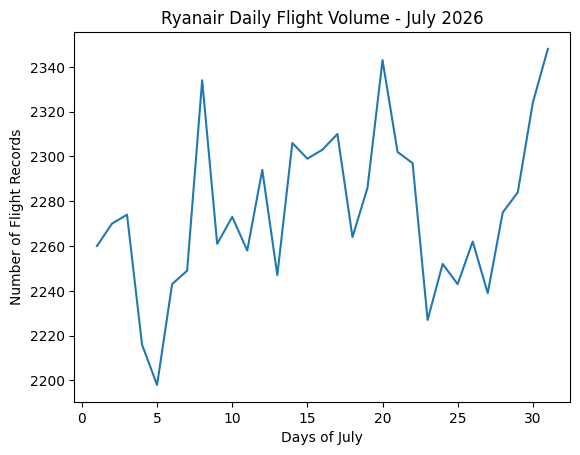

In [158]:
plt.plot(daily_flights.index,daily_flights.values)
plt.xlabel("Days of July")
plt.ylabel("Number of Flight Records")
plt.title("Ryanair Daily Flight Volume - July 2026")

plt.show()

In [159]:
# Q2.) Which days of the week have the highest Ryanair flight-record volume?

In [160]:
ryanair_clean["days_of_the_week"].value_counts()

days_of_the_week
Wednesday    11474
Friday       11457
Thursday     11385
Tuesday       9132
Monday        9072
Sunday        9040
Saturday      8981
Name: count, dtype: int64

In [161]:
# July 2026 doesn't contain the same number of every weekday.
# For example, some weekdays occur 5 times in July, while others occur only 4 times. So saying:
# "Wednesday is Ryanair's busiest weekday"

# just because Wednesday has 11,474 records would be misleading.
# We need to compare the average number of flight records per occurrence of each weekday, not just the monthly total.
# That's a proper EDA catch. 👀
# So our next step is to figure out:
# How many Mondays, Tuesdays, Wednesdays, etc. occurred in July 2026?

# We can actually derive that from our data. And I'm going to introduce you to another useful Pandas function for that: .nunique(), meaning number of unique values.

In [162]:
ryanair_clean.groupby("days_of_the_week")["dof"].nunique()

days_of_the_week
Friday       5
Monday       4
Saturday     4
Sunday       4
Thursday     5
Tuesday      4
Wednesday    5
Name: dof, dtype: int64

In [163]:
weekday_totals = ryanair_clean["days_of_the_week"].value_counts() 
weekday_occurrences = ryanair_clean.groupby("days_of_the_week")["dof"].nunique()

In [164]:
average_flights_by_weekday = weekday_totals / weekday_occurrences 

In [165]:
average_flights_by_weekday

days_of_the_week
Friday       2291.40
Monday       2268.00
Saturday     2245.25
Sunday       2260.00
Thursday     2277.00
Tuesday      2283.00
Wednesday    2294.80
dtype: float64

In [166]:
# now we reindex the order

In [167]:
weekday_order =["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

In [168]:
average_flights_by_weekday = average_flights_by_weekday.reindex(weekday_order)

In [169]:
average_flights_by_weekday 

days_of_the_week
Monday       2268.00
Tuesday      2283.00
Wednesday    2294.80
Thursday     2277.00
Friday       2291.40
Saturday     2245.25
Sunday       2260.00
dtype: float64

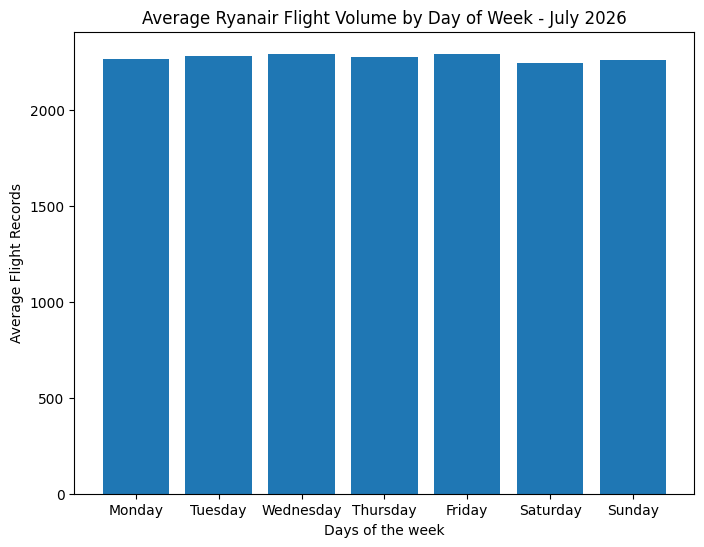

In [170]:
plt.figure(figsize=(8, 6))
plt.bar(average_flights_by_weekday.index,average_flights_by_weekday.values)
plt.xlabel("Days of the week")
plt.ylabel("Average Flight Records")
plt.title("Average Ryanair Flight Volume by Day of Week - July 2026")
plt.show()

In [171]:
# Q3.) Is average Ryanair flight-record volume different between weekdays and weekends?

In [172]:
ryanair_clean.head()

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,...,icao_operator,first_seen,last_seen,version,aircraft_model_clean,days_of_the_week,route,day_of_the_month,day_type,airport_pair
2,-3072630766419205805,4ca8db,RYR6AZ,2026-07-01,None,EGSS,,,EI-ENP,BOEING 737-8AS,...,RYR,2026-07-01 00:00:00,2026-07-01 01:05:50,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
21,4752231862766437797,4ca763,RYR9FM,2026-07-01,None,EIDW,,,EI-EFH,BOEING 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 02:29:20,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
142,5446074909086706693,4d2268,RYR65ER,2026-07-01,None,EGSS,,,9H-QDX,Boeing 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 00:42:50,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
185,-8766241914336995948,4ca9c3,RYR4957,2026-07-01,None,None,None,None,EI-EVC,BOEING 737-8AS,...,RYR,2026-07-01 00:00:05,2026-07-01 00:31:35,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN
197,-8275578619962495594,48c128,RYR36AQ,2026-07-01,None,LHBP,,,SP-RKI,Boeing 737-8AS (W),...,RYR,2026-07-01 00:00:05,2026-07-01 01:08:10,v0.0.2,Boeing 737-800,Wednesday,NaN,1,Weekday,NaN


In [173]:
ryanair_clean["day_type"].value_counts()

day_type
Weekday    52520
Weekend    18021
Name: count, dtype: int64

In [174]:
# same logic just like we did for question 2 

In [175]:
ryanair_clean.groupby("day_type")["dof"].nunique()

day_type
Weekday    23
Weekend     8
Name: dof, dtype: int64

In [176]:
day_type_totals = ryanair_clean["day_type"].value_counts()
day_type_occurrences = ryanair_clean.groupby("day_type")["dof"].nunique()

In [177]:
average_volume = day_type_totals / day_type_occurrences

In [178]:
average_volume

day_type
Weekday    2283.478261
Weekend    2252.625000
dtype: float64

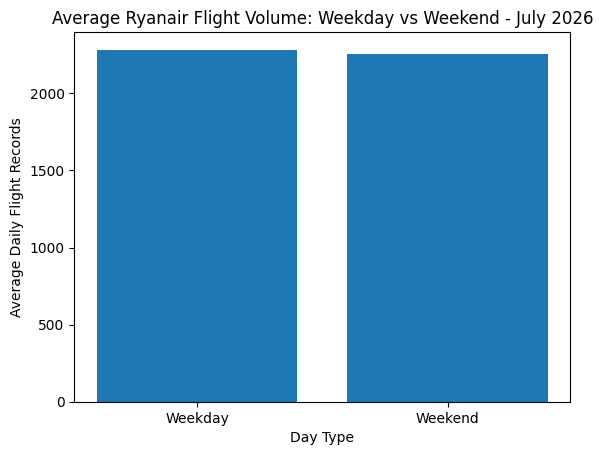

In [179]:
plt.bar(average_volume.index,average_volume.values)
plt.xlabel("Day Type")
plt.ylabel("Average Daily Flight Records")
plt.title("Average Ryanair Flight Volume: Weekday vs Weekend - July 2026")
plt.show()

In [180]:
# Q.4) Which departure airports have the most Ryanair flight records?

In [181]:
ryanair_clean["adep"].value_counts().head(10)

adep
EGSS    3779
EIDW    2673
LIME    2330
EBCI    1703
LEPA    1585
LEBL    1542
LEMG    1495
LEAL    1466
LIRF    1254
LEMD    1244
Name: count, dtype: int64

In [182]:
top_departure_airports = ryanair_clean["adep"].value_counts().head(10)

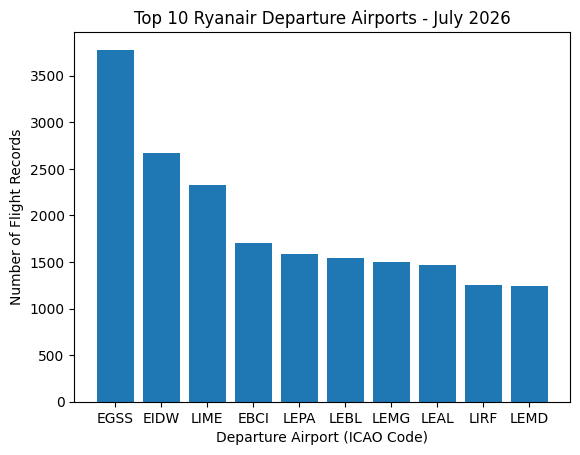

In [183]:
plt.bar(top_departure_airports.index,top_departure_airports.values)
plt.xlabel("Departure Airport (ICAO Code)")
plt.ylabel("Number of Flight Records")
plt.title("Top 10 Ryanair Departure Airports - July 2026")

plt.show()

In [184]:
# Q.5) Which destination airports have the most Ryanair flight records?

In [185]:
ryanair_clean["ades"].value_counts().head(10)

ades
EGSS    3768
EIDW    2671
LIME    2315
EBCI    1691
LEPA    1616
LEBL    1538
LEMG    1501
LEAL    1313
LIRF    1253
LEMD    1244
Name: count, dtype: int64

In [186]:
top_destination_airports = ryanair_clean["ades"].value_counts().head(10)

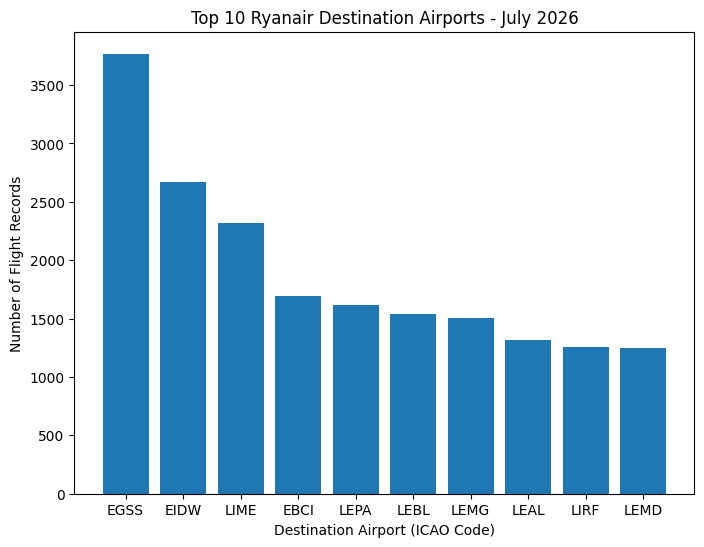

In [187]:
plt.figure(figsize=(8, 6))
plt.bar(top_destination_airports.index,top_destination_airports.values)
plt.xlabel("Destination Airport (ICAO Code)")
plt.ylabel("Number of Flight Records")
plt.title("Top 10 Ryanair Destination Airports - July 2026")

plt.show()

In [188]:
# Question 6: Which directional routes have the most Ryanair flight records among records with complete route information?

In [189]:
ryanair_clean["route"].value_counts().head(10)

route
EIDW-EGKK    167
EGKK-EIDW    167
EIDW-EGSS    162
EGSS-EIDW    159
EIDW-EGCC    132
EGCC-EIDW    132
EIDW-EGBB     99
EGBB-EIDW     97
LEBL-LEPA     90
LEMD-LEPA     89
Name: count, dtype: int64

In [190]:
top_routes = ryanair_clean["route"].value_counts().head(10)

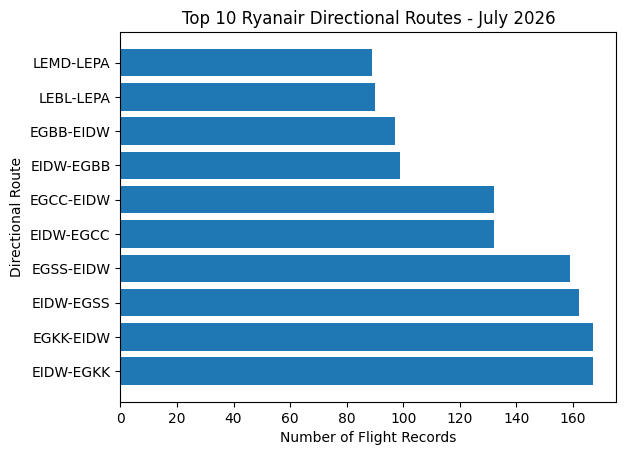

In [191]:
plt.barh(top_routes.index,top_routes.values)
plt.xlabel("Number of Flight Records")
plt.ylabel("Directional Route")
plt.title("Top 10 Ryanair Directional Routes - July 2026")

plt.show()

In [192]:
# Q.7.) Which airport pairs are most heavily served regardless of direction?

In [193]:
ryanair_clean["airport_pair"].value_counts().head(10)

airport_pair
EGKK-EIDW    334
EGSS-EIDW    321
EGCC-EIDW    264
EGBB-EIDW    196
LEMD-LEPA    176
EGGW-EIDW    171
EGSS-LEBL    170
LEBL-LEPA    169
EGPH-EIDW    168
EDDK-LEPA    168
Name: count, dtype: int64

In [194]:
top_airport_pairs = ryanair_clean["airport_pair"].value_counts().head(10)

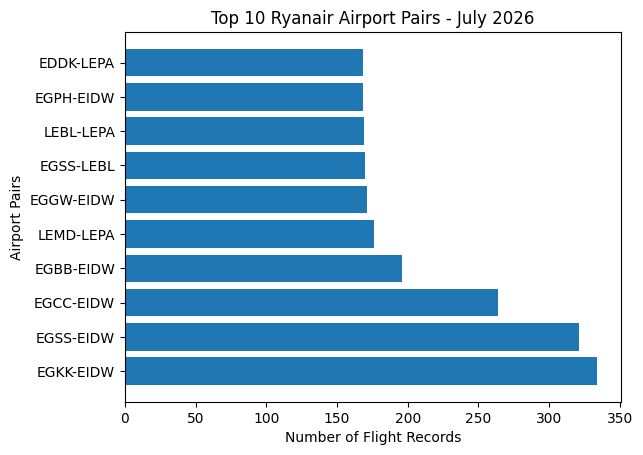

In [195]:
plt.barh(top_airport_pairs.index,top_airport_pairs.values)
plt.xlabel("Number of Flight Records")
plt.ylabel("Airport Pairs")
plt.title("Top 10 Ryanair Airport Pairs - July 2026")

plt.show()

In [196]:
# Q.8) What is the aircraft/fleet mix represented in Ryanair's July flight records?

In [197]:
ryanair_clean["aircraft_model_clean"].value_counts()

aircraft_model_clean
Boeing 737-800                         54422
Boeing 737 MAX 8-200                   15692
Airbus A320                              231
Boeing 737-700LJ45": "Learjet 45 XR      196
Name: count, dtype: int64

In [198]:
aircraft_count = ryanair_clean["aircraft_model_clean"].value_counts()

In [199]:
aircraft_percentage = aircraft_count / aircraft_count.sum()*100

In [200]:
aircraft_percentage

aircraft_model_clean
Boeing 737-800                         77.149459
Boeing 737 MAX 8-200                   22.245219
Airbus A320                             0.327469
Boeing 737-700LJ45": "Learjet 45 XR     0.277853
Name: count, dtype: float64

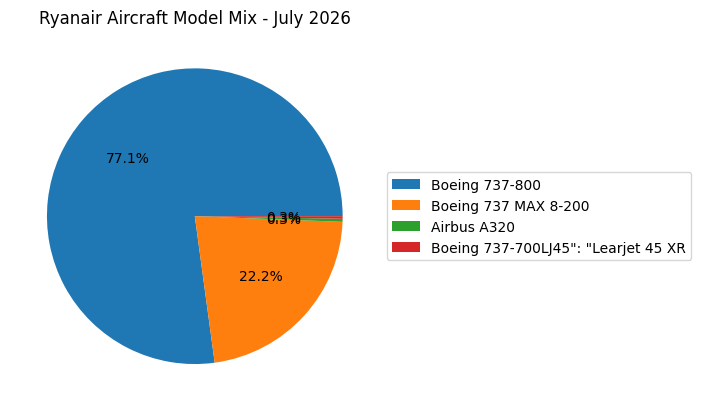

In [201]:
plt.pie(aircraft_count.values,autopct="%1.1f%%")
plt.legend(
    aircraft_count.index,
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)
plt.title("Ryanair Aircraft Model Mix - July 2026")
plt.show()

In [202]:
# Stage 5 — Multi-Month Data Pipeline

In [203]:
june_df = pd.read_parquet("https://www.eurocontrol.int/performance/data/download/OPDI/v002/flight_list/flight_list_202606.parquet")

In [204]:
june_df

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
0,7738640679768946872,06a140,QTR76G,2026-06-01 00:00:00,None,LIMC,,,A7-BFG,Boeing 777-FDZ,B77L,L2J,QTR,2026-06-01 00:00:00,2026-06-01 00:19:35,v0.0.2
1,3985633293991952184,406ac3,EXS32DA,2026-06-01 00:00:00,None,EGNX,,,G-GDFY,BOEING 737-86Q,B738,L2J,EXS,2026-06-01 00:00:00,2026-06-01 00:31:10,v0.0.2
2,4374218668032007968,4076ed,EXS216,2026-06-01 00:00:00,None,EGNM,,,G-DRTO,None,B738,L2J,None,2026-06-01 00:00:00,2026-06-01 01:22:00,v0.0.2
3,-7447521566355735364,407c26,TOM3DL,2026-06-01 00:00:00,None,EGNX,,,G-TUMU,None,B38M,L2J,None,2026-06-01 00:00:00,2026-06-01 01:08:45,v0.0.2
4,-8894794902249702336,4cae6b,RYR5417,2026-06-01 00:00:00,None,EIDW,,,None,None,None,None,None,2026-06-01 00:00:00,2026-06-01 01:32:20,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1558368,-6220429661216807133,4baa14,THY3VB,2026-06-30 00:00:00,None,LFTO,,,TC-JPT,A320 232,A320,L2J,THY,2026-06-30 23:57:05,2026-06-30 23:59:55,v0.0.2
1558369,7347390881359398767,4bcda2,SXS1BQ,2026-06-30 00:00:00,EGCC,None,,,TC-SMB,737-8 MAX,B38M,L2J,SXS,2026-06-30 23:57:20,2026-06-30 23:59:55,v0.0.2
1558370,-8214455683037709753,3e0ff1,CHXE5,2026-06-30 00:00:00,ETNH,None,,,None,None,None,None,None,2026-06-30 23:57:50,2026-06-30 23:59:55,v0.0.2
1558371,-5229046792308071270,4bcda1,SXS9WA,2026-06-30 00:00:00,EDLP,None,,,TC-SMA,None,B38M,L2J,None,2026-06-30 23:58:25,2026-06-30 23:59:55,v0.0.2


In [205]:
june_df.shape

(1558373, 16)

In [206]:
june_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1558373 entries, 0 to 1558372
Data columns (total 16 columns):
 #   Column               Non-Null Count    Dtype 
---  ------               --------------    ----- 
 0   id                   1558373 non-null  int64 
 1   icao24               1558373 non-null  object
 2   flt_id               1431446 non-null  object
 3   dof                  1558373 non-null  object
 4   adep                 881364 non-null   object
 5   ades                 928410 non-null   object
 6   adep_p               1210413 non-null  object
 7   ades_p               1210413 non-null  object
 8   registration         1243336 non-null  object
 9   model                872352 non-null   object
 10  typecode             1238762 non-null  object
 11  icao_aircraft_class  1050446 non-null  object
 12  icao_operator        698074 non-null   object
 13  first_seen           1558373 non-null  object
 14  last_seen            1558373 non-null  object
 15  version        

In [207]:
june_ryanair = june_df[june_df['icao_operator']=='RYR']

In [208]:
june_ryanair.shape

(66576, 16)

In [209]:
june_ryanair.duplicated().sum()

np.int64(0)

In [210]:
june_clean = june_ryanair.drop_duplicates().copy()

In [211]:
june_clean

,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
11,3988632138770172027,4ca850,RYR7LU,2026-06-01 00:00:00,None,EGSS,,,EI-EMI,BOEING 737-8AS,B738,L2J,RYR,2026-06-01 00:00:00,2026-06-01 00:19:00,v0.0.2
12,1633250418739724132,4ca646,RYR9060,2026-06-01 00:00:00,None,EGSS,,,EI-DYD,BOEING 737-8AS,B738,L2J,RYR,2026-06-01 00:00:00,2026-06-01 00:27:55,v0.0.2
13,8932584896061762009,4ca73f,RYR7SF,2026-06-01 00:00:00,None,EIDW,,,EI-EBX,BOEING 737-8AS,B738,L2J,RYR,2026-06-01 00:00:00,2026-06-01 00:40:40,v0.0.2
36,-5836437052099358699,4cae53,RYR61ME,2026-06-01 00:00:00,None,None,None,None,EI-IJC,Boeing 737 MAX 8-200,B38M,None,RYR,2026-06-01 00:00:05,2026-06-01 00:05:25,v0.0.2
70,3083287477338719274,4080c1,RUK27HZ,2026-06-01 00:00:00,None,EGSS,,,G-RUKO,Boeing 737-8AS,B738,None,RYR,2026-06-01 00:00:05,2026-06-01 01:06:25,v0.0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1558188,-5277129189845804875,4d2504,RYR42GU,2026-06-30 00:00:00,LFMN,None,,,9H-VVS,Boeing 737 MAX 8-200,B38M,None,RYR,2026-06-30 23:34:20,2026-06-30 23:59:55,v0.0.2
1558190,7248995429817416020,4ca8db,RYR6AZ,2026-06-30 00:00:00,ESGG,None,,,EI-ENP,BOEING 737-8AS,B738,L2J,RYR,2026-06-30 23:34:35,2026-06-30 23:59:55,v0.0.2
1558208,8681924400035986326,4ca809,RYR7667,2026-06-30 00:00:00,LZIB,None,,,EI-EKJ,BOEING 737-8AS,B738,L2J,RYR,2026-06-30 23:37:45,2026-06-30 23:59:55,v0.0.2
1558347,-3501522226662035206,4ca8d5,None,2026-06-30 00:00:00,None,None,None,None,EI-ENJ,BOEING 737-8AS,B738,L2J,RYR,2026-06-30 23:53:25,2026-06-30 23:58:35,v0.0.2


In [212]:
june_clean['dof'] = pd.to_datetime(june_clean['dof'])
june_clean['first_seen'] = pd.to_datetime(june_clean['first_seen'])
june_clean['last_seen'] = pd.to_datetime(june_clean['last_seen'])

In [213]:
june_clean[["dof","first_seen","last_seen"]].dtypes

dof           datetime64[ns]
first_seen    datetime64[ns]
last_seen     datetime64[ns]
dtype: object

In [214]:
june_clean.isnull().sum()

id                         0
icao24                     0
flt_id                  3239
dof                        0
adep                   15186
ades                   14675
adep_p                  5128
ades_p                  5128
registration               0
model                   2052
typecode                   0
icao_aircraft_class    15755
icao_operator              0
first_seen                 0
last_seen                  0
version                    0
dtype: int64

In [215]:
june_clean["typecode"].value_counts()

typecode
B738    51504
B38M    14708
A320      199
B737      165
Name: count, dtype: int64

In [216]:
june_clean[june_clean["model"].isnull()]["typecode"].value_counts()

typecode
B38M    1428
B738     624
Name: count, dtype: int64

In [217]:
aircraft_mapping = {
    "B738": "Boeing 737-800",
    "B38M": "Boeing 737 MAX 8-200",
    "A320": "Airbus A320",
    "B737": "Boeing 737-700"
}

In [218]:
june_clean["aircraft_model_clean"] = june_clean["typecode"].map(aircraft_mapping)

In [219]:
june_clean.isnull().sum()

id                          0
icao24                      0
flt_id                   3239
dof                         0
adep                    15186
ades                    14675
adep_p                   5128
ades_p                   5128
registration                0
model                    2052
typecode                    0
icao_aircraft_class     15755
icao_operator               0
first_seen                  0
last_seen                   0
version                     0
aircraft_model_clean        0
dtype: int64

In [220]:
june_clean[june_clean["icao_aircraft_class"].isnull()]["typecode"].value_counts()

typecode
B38M    11815
B738     3940
Name: count, dtype: int64

In [221]:
june_clean[
    june_clean["typecode"].isin(["B738", "B38M"])
]["icao_aircraft_class"].value_counts()

icao_aircraft_class
L2J    50457
Name: count, dtype: int64

In [222]:
june_clean["icao_aircraft_class"] = june_clean["icao_aircraft_class"].fillna("L2J")

In [223]:
june_clean.isnull().sum()

id                          0
icao24                      0
flt_id                   3239
dof                         0
adep                    15186
ades                    14675
adep_p                   5128
ades_p                   5128
registration                0
model                    2052
typecode                    0
icao_aircraft_class         0
icao_operator               0
first_seen                  0
last_seen                   0
version                     0
aircraft_model_clean        0
dtype: int64

In [224]:
# Notice what we deliberately haven't touched:
# flt_id       3,239
# adep        15,186
# ades        14,675
# adep_p       5,128
# ades_p       5,128
# model        2,052

# That's intentional. We already learned from July that we shouldn't blindly fill or delete these. The raw model can stay missing because we created aircraft_model_clean, and incomplete airport/flight-ID records can still be useful for other analyses.
# So June is behaving very similarly to July, which is great news for our pipeline.

In [225]:
(june_clean["first_seen"] > june_clean["last_seen"]).sum()

np.int64(0)

In [226]:
june_clean["days_of_the_week"] = june_clean["dof"].dt.day_name()

june_clean["day_of_the_month"] = june_clean["dof"].dt.day

In [227]:
june_clean[["dof", "days_of_the_week", "day_of_the_month"]].head()

,dof,days_of_the_week,day_of_the_month
11,2026-06-01,Monday,1
12,2026-06-01,Monday,1
13,2026-06-01,Monday,1
36,2026-06-01,Monday,1
70,2026-06-01,Monday,1


In [228]:
june_clean['day_type']= np.where(
    june_clean["days_of_the_week"].isin(['Saturday','Sunday']),
    "Weekend",
    "Weekday"
)

In [229]:
june_clean[["dof", "days_of_the_week", "day_of_the_month","day_type"]].head()

,dof,days_of_the_week,day_of_the_month,day_type
11,2026-06-01,Monday,1,Weekday
12,2026-06-01,Monday,1,Weekday
13,2026-06-01,Monday,1,Weekday
36,2026-06-01,Monday,1,Weekday
70,2026-06-01,Monday,1,Weekday


In [230]:
june_clean["route"] = june_clean["adep"] + "-" + june_clean["ades"]

In [231]:
june_clean[["adep", "ades", "route"]].head(10)

,adep,ades,route
11,None,EGSS,NaN
12,None,EGSS,NaN
13,None,EIDW,NaN
36,None,None,NaN
70,None,EGSS,NaN
79,None,EGNX,NaN
81,None,EGSS,NaN
103,None,EGCC,NaN
106,None,LIME,NaN
139,None,LEMD,NaN


In [232]:
june_clean[
    june_clean["adep"].notna() & june_clean["ades"].notna()
][["adep", "ades", "route"]].head(10)

,adep,ades,route
930,LEMD,LEPA,LEMD-LEPA
931,EGSS,EGPH,EGSS-EGPH
1098,EPWR,LGRP,EPWR-LGRP
1199,EPWR,LGRP,EPWR-LGRP
1364,LIMC,LIME,LIMC-LIME
1386,LIMC,LIME,LIMC-LIME
2021,LIME,EGSS,LIME-EGSS
2377,EVRA,LCPH,EVRA-LCPH
2443,LBSF,EGSS,LBSF-EGSS
2506,LCPH,LFOB,LCPH-LFOB


In [233]:
def new_airport_pair(row):
    if pd.isna(row['adep']) or pd.isna(row['ades']):
        return np.nan

    airports = sorted([row['adep'], row['ades']])
    return airports[0] + '-' + airports[1]

In [234]:
june_clean["airport_pair"] = june_clean.apply(new_airport_pair, axis=1)

In [235]:
june_clean[
    june_clean["airport_pair"].notna()
][["adep", "ades", "route", "airport_pair"]].head(10)

,adep,ades,route,airport_pair
930,LEMD,LEPA,LEMD-LEPA,LEMD-LEPA
931,EGSS,EGPH,EGSS-EGPH,EGPH-EGSS
1098,EPWR,LGRP,EPWR-LGRP,EPWR-LGRP
1199,EPWR,LGRP,EPWR-LGRP,EPWR-LGRP
1364,LIMC,LIME,LIMC-LIME,LIMC-LIME
1386,LIMC,LIME,LIMC-LIME,LIMC-LIME
2021,LIME,EGSS,LIME-EGSS,EGSS-LIME
2377,EVRA,LCPH,EVRA-LCPH,EVRA-LCPH
2443,LBSF,EGSS,LBSF-EGSS,EGSS-LBSF
2506,LCPH,LFOB,LCPH-LFOB,LCPH-LFOB


In [236]:
june_clean["dof"].min()

Timestamp('2026-06-01 00:00:00')

In [237]:
june_clean["dof"].max()

Timestamp('2026-06-30 00:00:00')

In [238]:
june_clean.duplicated().sum()

np.int64(0)

In [239]:
june_clean["icao_operator"].value_counts()

icao_operator
RYR    66576
Name: count, dtype: int64

In [240]:
june_clean["typecode"].value_counts()

typecode
B738    51504
B38M    14708
A320      199
B737      165
Name: count, dtype: int64

In [241]:
june_clean["route"].notnull().sum()

np.int64(41843)

In [242]:
june_clean["airport_pair"].notnull().sum()

np.int64(41843)